# Collaborative Filtering Embeddings (Matrix Factorisation)



# 1. Load Data

In [6]:
from google.colab import drive
import pandas as pd

# Load data

drive.mount('/content/gdrive')

try:
    base_path = '/content/gdrive/MyDrive/Music Recommender System/Recommender Systems (Project)/'
    print("Trying Samri's path")

    # chronological splits (with target variable is_listened)
    train_data = pd.read_csv(base_path + "train_data.csv")
    val_data = pd.read_csv(base_path + "val_data.csv")
    test_data = pd.read_csv(base_path + "test_data.csv")
    print('✓ Using Samriis Data')

except FileNotFoundError:
    base_path = '/content/gdrive/MyDrive/Recommender Systems (Project)/'
    print('Samriis path failed. Trying Leos Path...')
    # chronological splits (with target variable is_listened)
    train_data = pd.read_csv(base_path + "train_data.csv")
    val_data = pd.read_csv(base_path + "val_data.csv")
    test_data = pd.read_csv(base_path + "test_data.csv")
    print('✓ Using Leos Data')


Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
Trying Samri's path
✓ Using Samriis Data


In [8]:
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score

In [4]:
# formating for output

def hr(title=None, width=70, ch="─"):
    if title:
        title = f" {title} "
        side = (width - len(title)) // 2
        return ch * side + title + ch * (width - side - len(title))
    return ch * width

# overview shape train, val and test data

summary = pd.DataFrame({
    "rows": [len(train_data), len(val_data), len(test_data)],
    "cols": [train_data.shape[1], val_data.shape[1], test_data.shape[1]],
}, index=["train", "val", "test"])

print(hr("SHAPES"))
display(summary.style.format({"rows": "{:,}", "cols": "{:,}"}))

─────────────────────────────── SHAPES ───────────────────────────────


,rows,cols
train,"6,046,547",21
val,"755,818",21
test,"755,819",21


In [5]:
# slight class imbalance
vc = train_data["is_listened"].value_counts(dropna=False)
pct = train_data["is_listened"].value_counts(normalize=True, dropna=False) * 100

for k in vc.index:
    print(f"{k}: {vc[k]:,} ({pct[k]:.2f}%)")
print("-" * 40)
print(f"Total: {len(train_data):,}")

1: 4,176,051 (69.07%)
0: 1,870,496 (30.93%)
----------------------------------------
Total: 6,046,547


The dataset is split chronologically (02.preprocessing) using the listening timestamp (ts_listen) into train/validation/test. This avoids time leakage because training interactions happen before validation and test. The splits contain 6,046,547 (train), 755,818 (val), and 755,819 (test) rows.

Target and class balance.
The label is is_listened: 1 = listened > 30s, 0 = skipped < 30s. In the training set, there are 4,176,051 positives (69.07%) and 1,870,496 negatives (30.93%), so the classes are moderately imbalanced.


# 2. User/Item Map (Indexed Arrays for Pointwise Matrix Factorisation)

We build user2idx and item2idx from train data only to avoid leakage, then convert each training row into (user_index, item_index, label) arrays for matrix factorization. This produces 18,153 users and 403,288 items, with one indexed training example per interaction (6,046,547 rows).

In [7]:
# maps from train only so there is not leakage
all_users = pd.Index(train_data["user_id"].unique())
all_items = pd.Index(train_data["media_id"].unique())

user2idx = {u: i for i, u in enumerate(all_users)}
item2idx = {m: i for i, m in enumerate(all_items)}

print("num_users:", len(user2idx))
print("num_items:", len(item2idx))

# convert train to indexed arrays for MF training
u_idx_train = train_data["user_id"].map(user2idx).astype(np.int32).values
i_idx_train = train_data["media_id"].map(item2idx).astype(np.int32).values
y_train_mf  = train_data["is_listened"].astype(np.float32).values

print("train arrays:", u_idx_train.shape, i_idx_train.shape, y_train_mf.shape)
print("train pos rate:", y_train_mf.mean())



num_users: 18153
num_items: 403288
train arrays: (6046547,) (6046547,) (6046547,)
train pos rate: 0.6906505


# 3. Train Pointwise MF Model

We train a matrix factorization model with user and item embeddings (dim = 64) and user/item bias terms to predict is_listened using BCEWithLogitsLoss. We use class weighting for imbalance and L2 regularization, trained for 5 epochs with Adam (batch size 8192); the training loss decreases steadily across epochs.

In [9]:
# MF Pointwise

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

class PointwiseDS(Dataset):
    def __init__(self, u_idx, i_idx, y):
        self.u = torch.from_numpy(u_idx).long()
        self.i = torch.from_numpy(i_idx).long()
        self.y = torch.from_numpy(y).float()
    def __len__(self): return len(self.y)
    def __getitem__(self, idx): return self.u[idx], self.i[idx], self.y[idx]

class MFPointwise(nn.Module):
    def __init__(self, n_users, n_items, d):
        super().__init__()
        self.user_emb = nn.Embedding(n_users, d)
        self.item_emb = nn.Embedding(n_items, d)
        self.user_b = nn.Embedding(n_users, 1)
        self.item_b = nn.Embedding(n_items, 1)
        nn.init.normal_(self.user_emb.weight, std=0.01)
        nn.init.normal_(self.item_emb.weight, std=0.01)
        nn.init.zeros_(self.user_b.weight)
        nn.init.zeros_(self.item_b.weight)

    def forward(self, u, i):
        dot = (self.user_emb(u) * self.item_emb(i)).sum(dim=1)
        b = self.user_b(u).squeeze(1) + self.item_b(i).squeeze(1)
        return dot + b  # logits

emb_dim = 64
batch_size = 8192
epochs = 5
lr = 1e-2
l2_reg = 1e-6

ds = PointwiseDS(u_idx_train, i_idx_train, y_train_mf)
dl = DataLoader(ds, batch_size=batch_size, shuffle=True, num_workers=0)

model_cf = MFPointwise(len(user2idx), len(item2idx), emb_dim).to(device)
opt = torch.optim.Adam(model_cf.parameters(), lr=lr)

# imbalance weighting
pos = float(y_train_mf.mean())
neg = 1.0 - pos
pos_weight = torch.tensor([neg / max(pos, 1e-6)], device=device)
crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

for ep in range(1, epochs + 1):
    model_cf.train()
    total = 0.0
    nb = 0

    for u_b, i_b, y_b in dl:
        u_b = u_b.to(device, non_blocking=True)
        i_b = i_b.to(device, non_blocking=True)
        y_b = y_b.to(device, non_blocking=True)

        logits = model_cf(u_b, i_b)
        loss = crit(logits, y_b)

        if l2_reg > 0:
            loss = loss + l2_reg * (
                model_cf.user_emb(u_b).pow(2).mean() +
                model_cf.item_emb(i_b).pow(2).mean()
            )

        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()

        total += loss.item()
        nb += 1

    print(f"epoch {ep}/{epochs} - avg_loss: {total/max(nb,1):.5f}")

device: cpu
epoch 1/5 - avg_loss: 0.34777
epoch 2/5 - avg_loss: 0.27795
epoch 3/5 - avg_loss: 0.24710
epoch 4/5 - avg_loss: 0.23532
epoch 5/5 - avg_loss: 0.22881


In [12]:
#latent embeddings/collaborative signals (learned weight matrices)
print(model_cf.user_emb.weight.shape)
print(model_cf.item_emb.weight.shape)

torch.Size([18153, 64])
torch.Size([403288, 64])


The trained collaborative model learns latent user and item embedding matrices of size (18,153 × 64) and (403,288 × 64), which capture collaborative similarity patterns from listening behavior.

In [18]:
# save embeddings for 07.hybrid model

import pickle

with open(base_path + "user2idx_cf_pointwise_06.pkl", "wb") as f:
    pickle.dump(user2idx, f)

with open(base_path + "item2idx_cf_pointwise_06.pkl", "wb") as f:
    pickle.dump(item2idx, f)

torch.save(model_cf.state_dict(), base_path + "model_cf_pointwise_06.pt")

print("Saved pointwise CF artifacts:")
print(" - user2idx_cf_pointwise_06.pkl")
print(" - item2idx_cf_pointwise_06.pkl")
print(" - model_cf_pointwise_06.pt")

Saved pointwise CF artifacts:
 - user2idx_cf_pointwise_06.pkl
 - item2idx_cf_pointwise_06.pkl
 - model_cf_pointwise_06.pt


# 3. Compute  Pointwise Collaborative Filtering AUC

We evaluate the pointwise MF model using row-level ROC-AUC on validation and test. If a user or item is unseen in training (cold-start), we fall back to a simple popularity score (item_listen_count) and report the cold-start rate.

In [13]:

# CF AUC evaluation (clean)

# popularity fallback for cold-start rows
pop_lookup = train_data.groupby("media_id")["item_listen_count"].max().to_dict()

def cf_row_scores(df, model_cf, user2idx, item2idx, pop_lookup, device, batch_size=200000):
    """
    Row-level CF scores for AUC:
    - If (user_id, media_id) seen in TRAIN maps -> use MF logit score
    - Else -> fallback to popularity (item_listen_count) or 0.0
    Returns (scores, cold_start_rate)
    """
    # map ids -> indices (NaN if missing)
    u_map = df["user_id"].map(user2idx)
    i_map = df["media_id"].map(item2idx)
    ok = u_map.notna() & i_map.notna()

    scores = np.zeros(len(df), dtype=np.float32)

    # fallback for cold-start rows
    scores[~ok.values] = (
        df.loc[~ok, "media_id"]
        .map(pop_lookup)
        .fillna(0.0)
        .astype(np.float32)
        .values
    )
    cold_rate = float((~ok).mean())

    # score scorable rows in batches
    u_idx_ok = u_map[ok].astype(np.int64).values
    i_idx_ok = i_map[ok].astype(np.int64).values
    ok_pos = np.where(ok.values)[0]  # positions in original df

    model_cf.eval()
    with torch.no_grad():
        for start in range(0, len(u_idx_ok), batch_size):
            end = start + batch_size
            u_b = torch.from_numpy(u_idx_ok[start:end]).to(device)
            i_b = torch.from_numpy(i_idx_ok[start:end]).to(device)
            logits = model_cf(u_b, i_b).detach().cpu().numpy().astype(np.float32)
            scores[ok_pos[start:end]] = logits

    return scores, cold_rate

# Validation AUC
val_scores, val_cold = cf_row_scores(val_data, model_cf, user2idx, item2idx, pop_lookup, device)
auc_cf_val = roc_auc_score(val_data["is_listened"].values, val_scores)

print("\n" + "="*70)
print("Collaborative Filtering (Notebook 06) — Validation AUC")
print("="*70)
print(f"Validation AUC: {auc_cf_val:.6f}")
print(f"Cold-start fallback rate: {val_cold:.4%}")
print("="*70)

# Test AUC (comparable to baseline table)
test_scores, test_cold = cf_row_scores(test_data, model_cf, user2idx, item2idx, pop_lookup, device)
auc_cf_test = roc_auc_score(test_data["is_listened"].values, test_scores)

print("\n" + "="*70)
print("Collaborative Filtering (Notebook 06) — Test AUC")
print("="*70)
print(f"Test AUC: {auc_cf_test:.6f}")
print(f"Cold-start fallback rate: {test_cold:.4%}")
print("="*70)


Collaborative Filtering (Notebook 06) — Validation AUC
Validation AUC: 0.656581
Cold-start fallback rate: 13.9164%

Collaborative Filtering (Notebook 06) — Test AUC
Test AUC: 0.581723
Cold-start fallback rate: 27.7113%


In [15]:
def mf_only_auc(df, model_cf, user2idx, item2idx, device, batch_size=200000):
    u_map = df["user_id"].map(user2idx)
    i_map = df["media_id"].map(item2idx)
    ok = u_map.notna() & i_map.notna()

    df_ok = df.loc[ok].copy()
    u_idx_ok = u_map[ok].astype(np.int64).values
    i_idx_ok = i_map[ok].astype(np.int64).values

    scores = np.zeros(len(df_ok), dtype=np.float32)

    model_cf.eval()
    with torch.no_grad():
        for start in range(0, len(u_idx_ok), batch_size):
            end = start + batch_size
            u_b = torch.from_numpy(u_idx_ok[start:end]).to(device)
            i_b = torch.from_numpy(i_idx_ok[start:end]).to(device)
            logits = model_cf(u_b, i_b).detach().cpu().numpy().astype(np.float32)
            scores[start:end] = logits

    auc = roc_auc_score(df_ok["is_listened"].values, scores)
    coverage = float(ok.mean())
    return auc, coverage

auc_mf_only_test, coverage_test = mf_only_auc(test_data, model_cf, user2idx, item2idx, device)
print(f"MF-only Test AUC (scorable rows): {auc_mf_only_test:.6f}")
print(f"Coverage (scorable fraction of test): {coverage_test:.4%}")

MF-only Test AUC (scorable rows): 0.722961
Coverage (scorable fraction of test): 72.2887%


The model achieves Validation AUC = 0.6566 (cold-start 13.9%) and Test AUC = 0.5817 (cold-start 27.7%). To isolate MF quality when embeddings are available, we also report MF-only Test AUC = 0.7229 on the scorable subset (72.3% coverage), showing that performance is mainly limited by cold-start coverage rather than scoring quality.

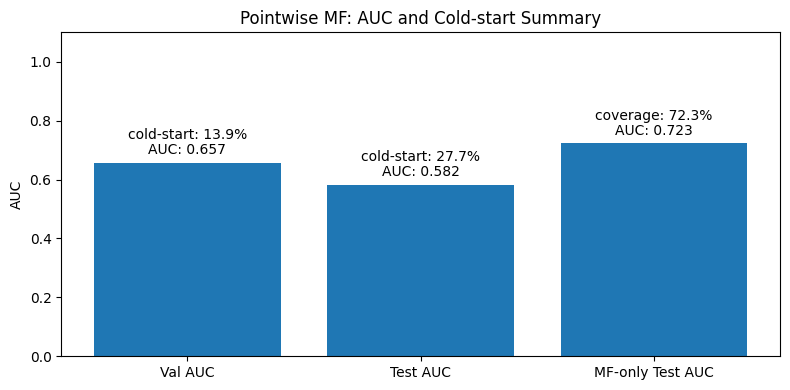

In [36]:
import matplotlib.pyplot as plt

# auc numbers
val_auc = 0.656581
test_auc = 0.581723
mf_only_test_auc = 0.722961

val_cold = 0.139164
test_cold = 0.277113
mf_only_coverage = 0.722887

labels = ["Val AUC", "Test AUC", "MF-only Test AUC"]
values = [val_auc, test_auc, mf_only_test_auc]

plt.figure(figsize=(8, 4))
plt.bar(labels, values)
plt.ylim(0, 1.10)  # extra headroom for labels
plt.ylabel("AUC")
plt.title("Pointwise MF: AUC and Cold-start Summary")

dy1, dy2 = 0.03, 0.08  # vertical offsets for two lines

# bar 0
plt.text(0, val_auc + dy1, f"AUC: {val_auc:.3f}", ha="center")
plt.text(0, val_cold + dy2, f"cold-start: {val_cold:.1%}", ha="center")

# bar 1
plt.text(1, test_auc + dy1, f"AUC: {test_auc:.3f}", ha="center")
plt.text(1, test_cold + dy2, f"cold-start: {test_cold:.1%}", ha="center")

# bar 2
plt.text(2, mf_only_test_auc + dy1, f"AUC: {mf_only_test_auc:.3f}", ha="center")
plt.text(2, mf_only_coverage + dy2, f"coverage: {mf_only_coverage:.1%}", ha="center")

plt.tight_layout()
plt.show()

# 4. Top K-Ranking Evaluation for Pointwise MF Model

In [22]:
# ranking evaluation
rng = np.random.default_rng(42)

K = 10
NUM_NEG = 100
MAX_POS = None

# pools for negative sampling
val_neg = (
    val_data[val_data["is_listened"] == 0]
    .groupby("user_id")["media_id"]
    .apply(lambda s: s.unique().tolist())
    .to_dict()
)
train_neg = (
    train_data[train_data["is_listened"] == 0]
    .groupby("user_id")["media_id"]
    .apply(lambda s: s.unique().tolist())
    .to_dict()
)

global_items = train_data["media_id"].unique()

# positives to evaluate
val_pos = val_data[val_data["is_listened"] == 1][["user_id", "media_id"]].copy()
if MAX_POS is not None and len(val_pos) > MAX_POS:
    val_pos = val_pos.sample(MAX_POS, random_state=42).reset_index(drop=True)

def sample_negs(u, n, true_item):
    pool = val_neg.get(u, [])
    if len(pool) < n:
        pool = pool + train_neg.get(u, [])
    pool = [x for x in dict.fromkeys(pool) if x != true_item]

    if len(pool) >= n:
        return rng.choice(pool, size=n, replace=False).tolist()

    # top up from global items
    need = n - len(pool)
    pool_set = set(pool)
    while len(pool) < n:
        cand = rng.choice(global_items)
        if cand != true_item and cand not in pool_set:
            pool.append(cand)
            pool_set.add(cand)
    return pool

def hr_ndcg_at_k(scores, true_index, k):
    rank = np.argsort(-scores)  # descending
    topk = rank[:k]
    if true_index in topk:
        pos = int(np.where(rank == true_index)[0][0])
        hr = 1.0
        ndcg = float(np.log(2.0) / np.log(pos + 2.0))
        return hr, ndcg
    return 0.0, 0.0

# evaluation
hrs, ndcgs = [], []
skipped = 0

model_cf.eval()
with torch.no_grad():
    for u, i_true in val_pos.itertuples(index=False):
        # must be scorable
        if (u not in user2idx) or (i_true not in item2idx):
            skipped += 1
            continue

        negs = sample_negs(u, NUM_NEG, i_true)
        items = [i_true] + negs[:NUM_NEG]

        # all items must be scorable
        if any(it not in item2idx for it in items):
            skipped += 1
            continue

        u_idx = user2idx[u]
        item_idx = np.array([item2idx[it] for it in items], dtype=np.int64)

        u_b = torch.tensor([u_idx], device=device)
        i_b = torch.from_numpy(item_idx).to(device)

        # pointwise MF logit scoring
        # score each candidate item for the user
        u_rep = u_b.repeat(len(item_idx))
        scores = model_cf(u_rep, i_b).detach().cpu().numpy()

        hr, ndcg = hr_ndcg_at_k(scores, true_index=0, k=K)
        hrs.append(hr)
        ndcgs.append(ndcg)

print("\n" + "="*70)
print(f"Pointwise MF — Ranking-style evaluation on VAL (K={K}, neg={NUM_NEG})")
print("="*70)
print(f"Evaluated positives: {len(hrs)} / {len(val_pos)}")
print(f"Skipped (cold-start/unscorable): {skipped} ({skipped/max(len(val_pos),1):.2%})")
print(f"HitRate@{K}: {np.mean(hrs):.4f}")
print(f"NDCG@{K}: {np.mean(ndcgs):.4f}")
print("="*70)


Pointwise MF — Ranking-style evaluation on VAL (K=10, neg=100)
Evaluated positives: 274793 / 508641
Skipped (cold-start/unscorable): 233848 (45.98%)
HitRate@10: 0.4363
NDCG@10: 0.2465


In [23]:
rng = np.random.default_rng(42)

K = 10
NUM_NEG = 100
MAX_POS = None

# pools for negative sampling (TEST + TRAIN fallback)
test_neg = (
    test_data[test_data["is_listened"] == 0]
    .groupby("user_id")["media_id"]
    .apply(lambda s: s.unique().tolist())
    .to_dict()
)
train_neg = (
    train_data[train_data["is_listened"] == 0]
    .groupby("user_id")["media_id"]
    .apply(lambda s: s.unique().tolist())
    .to_dict()
)

global_items = train_data["media_id"].unique()

test_pos = test_data[test_data["is_listened"] == 1][["user_id","media_id"]].copy()
if MAX_POS is not None and len(test_pos) > MAX_POS:
    test_pos = test_pos.sample(MAX_POS, random_state=42).reset_index(drop=True)

def sample_negs_test(u, n, true_item):
    pool = test_neg.get(u, [])
    if len(pool) < n:
        pool = pool + train_neg.get(u, [])
    pool = [x for x in dict.fromkeys(pool) if x != true_item]

    if len(pool) >= n:
        return rng.choice(pool, size=n, replace=False).tolist()

    pool_set = set(pool)
    while len(pool) < n:
        cand = rng.choice(global_items)
        if cand != true_item and cand not in pool_set:
            pool.append(cand)
            pool_set.add(cand)
    return pool

def hr_ndcg_at_k(scores, true_index, k):
    rank = np.argsort(-scores)
    topk = rank[:k]
    if true_index in topk:
        pos = int(np.where(rank == true_index)[0][0])
        hr = 1.0
        ndcg = float(np.log(2.0) / np.log(pos + 2.0))
        return hr, ndcg
    return 0.0, 0.0

hrs, ndcgs = [], []
skipped = 0

model_cf.eval()
with torch.no_grad():
    for u, i_true in test_pos.itertuples(index=False):
        if (u not in user2idx) or (i_true not in item2idx):
            skipped += 1
            continue

        negs = sample_negs_test(u, NUM_NEG, i_true)
        items = [i_true] + negs[:NUM_NEG]

        if any(it not in item2idx for it in items):
            skipped += 1
            continue

        u_idx = user2idx[u]
        item_idx = np.array([item2idx[it] for it in items], dtype=np.int64)

        u_b = torch.tensor([u_idx], device=device)
        i_b = torch.from_numpy(item_idx).to(device)

        u_rep = u_b.repeat(len(item_idx))
        scores = model_cf(u_rep, i_b).detach().cpu().numpy()

        hr, ndcg = hr_ndcg_at_k(scores, true_index=0, k=K)
        hrs.append(hr); ndcgs.append(ndcg)

print("\n" + "="*70)
print(f"Pointwise MF — Ranking-style eval on TEST (K={K}, neg={NUM_NEG})")
print("="*70)
print(f"Evaluated: {len(hrs)} / {len(test_pos)}")
print(f"Skipped (cold-start/unscorable): {skipped} ({skipped/max(len(test_pos),1):.2%})")
print(f"HitRate@{K}: {np.mean(hrs):.4f}")
print(f"NDCG@{K}: {np.mean(ndcgs):.4f}")
print("="*70)


Pointwise MF — Ranking-style eval on TEST (K=10, neg=100)
Evaluated: 180864 / 485219
Skipped (cold-start/unscorable): 304355 (62.73%)
HitRate@10: 0.4110
NDCG@10: 0.2287


In addition to the row-level AUC, we evaluate the MF model in a recommender setting: for each listened event, we rank the true item against 100 sampled negatives and compute HitRate@10 and NDCG@10.

On validation, we obtain HR@10 = 0.436 and NDCG@10 = 0.247 on scorable positives (skipped 46.0%). On test, we obtain HR@10 = 0.411 and NDCG@10 = 0.229 (skipped 62.7%), showing similar ranking quality but lower coverage in the later test period.

# Pairwise MF (BRP)

In [27]:

rng = np.random.default_rng(42)

# global pool of items from train (bigger coverage)
global_items = train_data["media_id"].unique()

def sample_global_negative(user_id, true_pos_item):
    """Sample an item the user has NOT listened to (train positives)."""
    seen_pos = set(i for i, w in user_pos_w.get(user_id, []))
    while True:
        cand = rng.choice(global_items)
        if cand != true_pos_item and cand not in seen_pos:
            return cand

# Build triples for ALL users:
# if user has explicit negatives -> sample from them (weighted by w_neg)
# else -> sample from global_items (unobserved negative)
w_trip = []  # (user_id, pos_media_id, neg_media_id, weight=w_pos)

for u, pos_list in user_pos_w.items():
    neg_list = user_neg_w.get(u)  # may be None

    if neg_list:  # explicit negatives exist
        neg_items = np.array([i for i, w in neg_list], dtype=object)
        neg_probs = np.array([w for i, w in neg_list], dtype=np.float64)
        neg_probs = neg_probs / neg_probs.sum()

        for i_pos, w_pos in pos_list:
            i_neg = rng.choice(neg_items, p=neg_probs)
            w_trip.append((u, i_pos, i_neg, w_pos))

    else:  # no explicit negatives -> global sampled negatives
        for i_pos, w_pos in pos_list:
            i_neg = sample_global_negative(u, i_pos)
            w_trip.append((u, i_pos, i_neg, w_pos))

print("num training triples:", len(w_trip))
print("users covered in triples:", len({t[0] for t in w_trip}))

num training triples: 2296375
users covered in triples: 17982


In [30]:

# Build maps from triples
users = pd.Index([t[0] for t in w_trip]).unique()
items = pd.Index([t[1] for t in w_trip] + [t[2] for t in w_trip]).unique()

user2idx = {u: idx for idx, u in enumerate(users)}
item2idx = {i: idx for idx, i in enumerate(items)}

num_users = len(user2idx)
num_items = len(item2idx)

# Convert triples -> index arrays for PyTorch training
u_idx     = np.array([user2idx[t[0]] for t in w_trip], dtype=np.int32)
pos_i_idx = np.array([item2idx[t[1]] for t in w_trip], dtype=np.int32)
neg_i_idx = np.array([item2idx[t[2]] for t in w_trip], dtype=np.int32)
w         = np.array([t[3] for t in w_trip], dtype=np.float32)

print("num_users:", num_users, "num_items:", num_items)
print("arrays:", u_idx.shape, pos_i_idx.shape, neg_i_idx.shape, w.shape)

num_users: 17982 num_items: 375016
arrays: (2296375,) (2296375,) (2296375,) (2296375,)


In [31]:
emb_dim = 64
batch_size = 8192
epochs = 10
lr = 1e-2
weight_clip = 10.0
l2_reg = 1e-6

# dataset
class BPRTriples(Dataset):
    def __init__(self, u, pi, ni, w):
        self.u  = torch.from_numpy(u).long()
        self.pi = torch.from_numpy(pi).long()
        self.ni = torch.from_numpy(ni).long()
        self.w  = torch.from_numpy(w).float()

    def __len__(self):
        return self.u.shape[0]

    def __getitem__(self, idx):
        return self.u[idx], self.pi[idx], self.ni[idx], self.w[idx]

ds = BPRTriples(u_idx, pos_i_idx, neg_i_idx, w)
dl = DataLoader(ds, batch_size=batch_size, shuffle=True, num_workers=0)


In [33]:
# MF bpr model
class MF(nn.Module):
    def __init__(self, n_users, n_items, d):
        super().__init__()
        self.user_emb = nn.Embedding(n_users, d)
        self.item_emb = nn.Embedding(n_items, d)
        nn.init.normal_(self.user_emb.weight, std=0.01)
        nn.init.normal_(self.item_emb.weight, std=0.01)

    def score(self, u, i):
        return (self.user_emb(u) * self.item_emb(i)).sum(dim=1)

model = MF(num_users, num_items, emb_dim).to(device)
opt = torch.optim.Adam(model.parameters(), lr=lr)

def weighted_bpr_loss(pos_scores, neg_scores, weights):
    x = pos_scores - neg_scores
    loss_per = -torch.log(torch.sigmoid(x) + 1e-12)
    w_clipped = torch.clamp(weights, 1.0, weight_clip)
    return (loss_per * w_clipped).mean()

In [34]:


# train
for epoch in range(1, epochs + 1):
    model.train()
    total_loss = 0.0
    n_batches = 0

    for u_b, p_b, n_b, w_b in dl:
        u_b = u_b.to(device, non_blocking=True)
        p_b = p_b.to(device, non_blocking=True)
        n_b = n_b.to(device, non_blocking=True)
        w_b = w_b.to(device, non_blocking=True)

        pos_s = model.score(u_b, p_b)
        neg_s = model.score(u_b, n_b)
        loss = weighted_bpr_loss(pos_s, neg_s, w_b)

        if l2_reg > 0:
            loss = loss + l2_reg * (
                model.user_emb(u_b).pow(2).mean()
                + model.item_emb(p_b).pow(2).mean()
                + model.item_emb(n_b).pow(2).mean()
            )

        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()

        total_loss += loss.item()
        n_batches += 1

    print(f"epoch {epoch}/{epochs} - avg_loss: {total_loss / max(n_batches,1):.5f}")

epoch 1/10 - avg_loss: 0.95434
epoch 2/10 - avg_loss: 0.51340
epoch 3/10 - avg_loss: 0.32744
epoch 4/10 - avg_loss: 0.24878
epoch 5/10 - avg_loss: 0.20154
epoch 6/10 - avg_loss: 0.16967
epoch 7/10 - avg_loss: 0.14650
epoch 8/10 - avg_loss: 0.12959
epoch 9/10 - avg_loss: 0.11564
epoch 10/10 - avg_loss: 0.10413


In [ ]:

k = 10
num_neg = 100
MAX_EVAL_POS = None
rng = np.random.default_rng(42)

# 1) Build negative pools (val first, then train)
val_neg = (
    val_data[val_data["is_listened"] == 0]
    .groupby("user_id")["media_id"]
    .apply(lambda s: s.unique().tolist())
    .to_dict()
)
train_neg = (
    train_data[train_data["is_listened"] == 0]
    .groupby("user_id")["media_id"]
    .apply(lambda s: s.unique().tolist())
    .to_dict()
)

# global pool (train items)
global_items = train_data["media_id"].unique()

# positives to evaluate
val_pos = val_data[val_data["is_listened"] == 1][["user_id", "media_id"]].copy()
if MAX_EVAL_POS is not None and len(val_pos) > MAX_EVAL_POS:
    val_pos = val_pos.sample(MAX_EVAL_POS, random_state=42).reset_index(drop=True)

def sample_negs(u, n, true_item):
    pool = val_neg.get(u, [])
    if len(pool) < n:
        pool = pool + train_neg.get(u, [])
    # unique + remove true
    pool = [x for x in dict.fromkeys(pool) if x != true_item]

    if len(pool) >= n:
        return rng.choice(pool, size=n, replace=False).tolist()

    # top up from global pool
    need = n - len(pool)
    extra = []
    pool_set = set(pool)
    while len(extra) < need:
        cand = rng.choice(global_items)
        if cand != true_item and cand not in pool_set:
            extra.append(cand)
            pool_set.add(cand)
    return pool + extra

def hr_ndcg_at_k(scores, true_index, k):
    rank = np.argsort(-scores)        # sorted indices (desc)
    topk = rank[:k]
    if true_index in topk:
        pos = int(np.where(rank == true_index)[0][0])  # 0-based position
        hr = 1.0
        ndcg = float(np.log(2.0) / np.log(pos + 2.0))
        return hr, ndcg
    return 0.0, 0.0

# extract embeddings for fast scoring
model.eval()
with torch.no_grad():
    U = model.user_emb.weight.detach().cpu().numpy()
    V = model.item_emb.weight.detach().cpu().numpy()

hrs, ndcgs = [], []
skipped = 0

for u, i_true in val_pos.itertuples(index=False):
    # cold-start check (MF cannot score unseen users/items)
    if (u not in user2idx) or (i_true not in item2idx):
        skipped += 1
        continue

    negs = sample_negs(u, num_neg, i_true)
    items = [i_true] + negs[:num_neg]

    # all candidates have embeddings
    if any(it not in item2idx for it in items):
        skipped += 1
        continue

    uvec = U[user2idx[u]]
    ivecs = V[np.array([item2idx[it] for it in items])]
    scores = ivecs @ uvec

    hr, ndcg = hr_ndcg_at_k(scores, true_index=0, k=k)
    hrs.append(hr); ndcgs.append(ndcg)

print(f"Evaluated positives: {len(hrs)} | Skipped (cold-start): {skipped}")
print(f"HitRate@{k}: {np.mean(hrs):.4f}")
print(f"NDCG@{k}: {np.mean(ndcgs):.4f}")

In [ ]:
from sklearn.metrics import roc_auc_score

MAX_AUC_POS = None
rng = np.random.default_rng(42)
val_pos_auc = val_data[val_data["is_listened"] == 1][["user_id","media_id"]].copy()
if MAX_AUC_POS is not None and len(val_pos_auc) > MAX_AUC_POS:
    val_pos_auc = val_pos_auc.sample(MAX_AUC_POS, random_state=42).reset_index(drop=True)

y_true = []
y_score = []
skipped_auc = 0

for u, i_pos in val_pos_auc.itertuples(index=False):
    if (u not in user2idx) or (i_pos not in item2idx):
        skipped_auc += 1
        continue

    # sample one negative for this user
    negs = sample_negs(u, 1, i_pos)
    i_neg = negs[0]

    if i_neg not in item2idx:
        skipped_auc += 1
        continue

    uvec = U[user2idx[u]]
    s_pos = float(V[item2idx[i_pos]] @ uvec)
    s_neg = float(V[item2idx[i_neg]] @ uvec)

    y_true.extend([1, 0])
    y_score.extend([s_pos, s_neg])

auc = roc_auc_score(y_true, y_score)
print(f"AUC pairs used: {len(y_true)//2} | Skipped: {skipped_auc}")
print(f"ROC-AUC: {auc:.4f}")

## Leos Test Model
Below I am testing with enhanced model configurations

  - Added validation AUC computation after each epoch
  - Implemented early stopping when validation doesn't improve
  - Can train for more epochs adaptively (up to 20) instead of fixed 3

In [24]:
def weighted_bpr_loss(pos_scores, neg_scores, weights):
    # BPR: -log(sigmoid(pos - neg))
    x = pos_scores - neg_scores
    loss_per = -torch.log(torch.sigmoid(x) + 1e-12)

    # clip weights for stability
    w_clipped = torch.clamp(weights, 1.0, weight_clip)
    return (loss_per * w_clipped).mean()

In [25]:
def compute_validation_auc(model, user2idx, item2idx, val_pos, val_neg, train_neg, global_items, num_neg=100,
  max_eval=5000):
    """Compute AUC on validation data"""
    model.eval()

    with torch.no_grad():
        U = model.user_emb.weight.detach().cpu().numpy()
        V = model.item_emb.weight.detach().cpu().numpy()

    y_true = []
    y_score = []
    skipped = 0

    val_pos_sample = val_pos.sample(min(max_eval, len(val_pos)), random_state=42).reset_index(drop=True)

    for u, i_pos in val_pos_sample.itertuples(index=False):
        if (u not in user2idx) or (i_pos not in item2idx):
            skipped += 1
            continue

        negs = sample_negs(u, num_neg, i_pos)
        i_neg = negs[0]

        if i_neg not in item2idx:
            skipped += 1
            continue

        uvec = U[user2idx[u]]
        s_pos = float(V[item2idx[i_pos]] @ uvec)
        s_neg = float(V[item2idx[i_neg]] @ uvec)

        y_true.extend([1, 0])
        y_score.extend([s_pos, s_neg])

    if len(y_true) == 0:
        return 0.0

    auc = roc_auc_score(y_true, y_score)
    return auc

In [35]:
import numpy as np
from sklearn.metrics import roc_auc_score

# ===== SETUP =====
rng = np.random.default_rng(42)

# Prepare validation data
val_pos = val_data[val_data["is_listened"] == 1][["user_id", "media_id"]].copy()

val_neg = (
    val_data[val_data["is_listened"] == 0]
    .groupby("user_id")["media_id"]
    .apply(lambda s: s.unique().tolist())
    .to_dict()
)

train_neg = (
    train_data[train_data["is_listened"] == 0]
    .groupby("user_id")["media_id"]
    .apply(lambda s: s.unique().tolist())
    .to_dict()
)

global_items = train_data["media_id"].unique()

print("✓ Validation data prepared!")
print(f"  val_pos samples: {len(val_pos)}")

# ===== HELPER FUNCTIONS =====
def sample_negs(u, n, true_item):
    """Sample negative items for a user"""
    pool = val_neg.get(u, [])
    if len(pool) < n:
        pool = pool + train_neg.get(u, [])

    pool = [x for x in dict.fromkeys(pool) if x != true_item]

    if len(pool) >= n:
        return rng.choice(pool, size=n, replace=False).tolist()

    if len(pool) == 0:
        return None

    return rng.choice(pool, size=n, replace=True).tolist()

def compute_validation_auc(model, user2idx, item2idx, val_pos, val_neg, train_neg, global_items, num_neg=100,
  max_eval=5000):
    """Compute AUC on validation data"""
    model.eval()

    with torch.no_grad():
        U = model.user_emb.weight.detach().cpu().numpy()
        V = model.item_emb.weight.detach().cpu().numpy()

    y_true = []
    y_score = []
    skipped = 0

    val_pos_sample = val_pos.sample(min(max_eval, len(val_pos)), random_state=42).reset_index(drop=True)

    for u, i_pos in val_pos_sample.itertuples(index=False):
        if (u not in user2idx) or (i_pos not in item2idx):
            skipped += 1
            continue

        negs = sample_negs(u, num_neg, i_pos)
        if negs is None:
            skipped += 1
            continue

        i_neg = negs[0]

        if i_neg not in item2idx:
            skipped += 1
            continue

        uvec = U[user2idx[u]]
        s_pos = float(V[item2idx[i_pos]] @ uvec)
        s_neg = float(V[item2idx[i_neg]] @ uvec)

        y_true.extend([1, 0])
        y_score.extend([s_pos, s_neg])

    if len(y_true) == 0:
        return 0.0

    auc = roc_auc_score(y_true, y_score)
    return auc

# ===== TRAINING WITH VALIDATION & EARLY STOPPING =====
best_val_auc = 0.0
patience = 5
patience_counter = 0
max_epochs = 20

print("\n" + "="*60)
print("STARTING IMPROVED TRAINING")
print("="*60)

for epoch in range(1, max_epochs + 1):
    # TRAIN
    model.train()
    total_loss = 0.0
    n_batches = 0

    for u_b, p_b, n_b, w_b in dl:
        u_b = u_b.to(device, non_blocking=True)
        p_b = p_b.to(device, non_blocking=True)
        n_b = n_b.to(device, non_blocking=True)
        w_b = w_b.to(device, non_blocking=True)

        pos_s = model.score(u_b, p_b)
        neg_s = model.score(u_b, n_b)
        loss = weighted_bpr_loss(pos_s, neg_s, w_b)

        if l2_reg > 0:
            loss = loss + l2_reg * (
                model.user_emb(u_b).pow(2).mean() +
                model.item_emb(p_b).pow(2).mean() +
                model.item_emb(n_b).pow(2).mean()
            )

        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()

        total_loss += loss.item()
        n_batches += 1

    train_loss_avg = total_loss / max(n_batches, 1)

    # VALIDATE
    val_auc = compute_validation_auc(model, user2idx, item2idx, val_pos, val_neg, train_neg, global_items)

    # EARLY STOPPING
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        patience_counter = 0
        print(f"epoch {epoch}/{max_epochs} - train_loss: {train_loss_avg:.5f}, val_auc: {val_auc:.4f} ✓IMPROVED")
    else:
        patience_counter += 1
        print(f"epoch {epoch}/{max_epochs} - train_loss: {train_loss_avg:.5f}, val_auc: {val_auc:.4f}({patience_counter}/{patience})")

        if patience_counter >= patience:
            print(f"\n✗ Early stopping at epoch {epoch}. No improvement for {patience} epochs.")
            break

print("\n" + "="*60)
print(f"TRAINING COMPLETE")
print(f"Best Validation AUC: {best_val_auc:.4f}")
print("="*60)

✓ Validation data prepared!
  val_pos samples: 508641

STARTING IMPROVED TRAINING
epoch 1/20 - train_loss: 0.09630, val_auc: 0.7360 ✓IMPROVED
epoch 2/20 - train_loss: 0.08925, val_auc: 0.7322(1/5)
epoch 3/20 - train_loss: 0.08275, val_auc: 0.7374 ✓IMPROVED
epoch 4/20 - train_loss: 0.07761, val_auc: 0.7269(1/5)
epoch 5/20 - train_loss: 0.07454, val_auc: 0.7345(2/5)
epoch 6/20 - train_loss: 0.07145, val_auc: 0.7299(3/5)
epoch 7/20 - train_loss: 0.06975, val_auc: 0.7289(4/5)
epoch 8/20 - train_loss: 0.06819, val_auc: 0.7261(5/5)

✗ Early stopping at epoch 8. No improvement for 5 epochs.

TRAINING COMPLETE
Best Validation AUC: 0.7374


In [ ]:
# Prepare test data for evaluation
test_pos = test_data[test_data["is_listened"] == 1][["user_id", "media_id"]].copy()

test_neg = (
    test_data[test_data["is_listened"] == 0]
    .groupby("user_id")["media_id"]
    .apply(lambda s: s.unique().tolist())
    .to_dict()
)

print("✓ Test data prepared!")
print(f"  test_pos samples: {len(test_pos)}")

# Compute test AUC
test_auc = compute_validation_auc(
    model, user2idx, item2idx,
    test_pos, test_neg, train_neg, global_items
)
print(f"FINAL TEST AUC: {test_auc:.4f}")

✓ Test data prepared!
  test_pos samples: 485219
FINAL TEST AUC: 0.7414


In [ ]:
# ===== RESET RNG FOR FAIR EVALUATION =====
rng = np.random.default_rng(42)

# ===== COMPUTE HitRate@10 and NDCG@10 on TEST SET =====

k = 10
num_neg = 100
max_eval = 20000

# Extract embeddings from trained model
model.eval()
with torch.no_grad():
    U = model.user_emb.weight.detach().cpu().numpy()
    V = model.item_emb.weight.detach().cpu().numpy()

# Helper function for ranking metrics
def hr_ndcg_at_k(scores, true_index, k):
    rank = np.argsort(-scores)
    topk = rank[:k]
    if true_index in topk:
        pos = int(np.where(rank == true_index)[0][0])
        hr = 1.0
        ndcg = np.log(2.0) / np.log(pos + 2.0)
        return hr, ndcg
    return 0.0, 0.0

def sample_negs_for_test(u, n, true_item):
    """Sample negatives for test user"""
    pool = test_neg.get(u, [])  # ← USE test_neg
    if len(pool) < n:
        pool = pool + train_neg.get(u, [])
    pool = [x for x in dict.fromkeys(pool) if x != true_item]

    if len(pool) >= n:
        return rng.choice(pool, size=n, replace=False).tolist()
    if len(pool) == 0:
        return None
    return rng.choice(pool, size=n, replace=True).tolist()

# Evaluate on test set
test_pos_sample = test_pos.sample(min(max_eval, len(test_pos)), random_state=42).reset_index(drop=True)  # ←USE test_pos

hrs, ndcgs = [], []
skipped = 0

for u, i_true in test_pos_sample.itertuples(index=False):
    if (u not in user2idx) or (i_true not in item2idx):
        skipped += 1
        continue

    negs = sample_negs_for_test(u, num_neg, i_true)
    if negs is None:
        skipped += 1
        continue

    items = [i_true] + negs[:num_neg]
    item_idx = [item2idx.get(it) for it in items]

    if any(x is None for x in item_idx):
        skipped += 1
        continue

    uvec = U[user2idx[u]]
    ivecs = V[np.array(item_idx)]
    scores = ivecs @ uvec

    hr, ndcg = hr_ndcg_at_k(scores, true_index=0, k=k)
    hrs.append(hr)
    ndcgs.append(ndcg)

print(f"\n" + "="*60)
print(f"TEST SET - RANKING METRICS (HitRate@{k}, NDCG@{k})")
print(f"="*60)
print(f"Evaluated: {len(hrs)} | Skipped (cold-start): {skipped}")
print(f"HitRate@{k}: {np.mean(hrs):.4f}")
print(f"NDCG@{k}: {np.mean(ndcgs):.4f}")
print("="*60)


TEST SET - RANKING METRICS (HitRate@10, NDCG@10)
Evaluated: 6161 | Skipped (cold-start): 13839
HitRate@10: 0.4277
NDCG@10: 0.2635


### Test 1A: Reproduce the Epoch 1 Peak

Question: Does epoch 1 peak happen every time?

In [ ]:
# Hyperparameters
weight_clip = 10
l2_reg = 1e-6
emb_dim = 64
lr = 1e-2

def weighted_bpr_loss(pos_scores, neg_scores, weights):
    x = pos_scores - neg_scores
    loss_per = -torch.log(torch.sigmoid(x) + 1e-12)
    w_clipped = torch.clamp(weights, 1.0, weight_clip)
    return (loss_per * w_clipped).mean()

def compute_validation_auc(model, user2idx, item2idx, val_pos, val_neg, train_neg, global_items, num_neg=100, max_eval=5000):
    model.eval()
    rng = np.random.default_rng(42)
    with torch.no_grad():
        U = model.user_emb.weight.detach().cpu().numpy()
        V = model.item_emb.weight.detach().cpu().numpy()

    y_true, y_score = [], []
    val_pos_sample = val_pos.sample(min(max_eval, len(val_pos)), random_state=42).reset_index(drop=True)

    for u, i_pos in val_pos_sample.itertuples(index=False):
        if (u not in user2idx) or (i_pos not in item2idx):
            continue
        pool = val_neg.get(u, []) + train_neg.get(u, [])
        pool = [x for x in dict.fromkeys(pool) if x != i_pos]
        if len(pool) == 0:
            continue
        if len(pool) >= num_neg:
            negs = rng.choice(pool, size=num_neg, replace=False).tolist()
        else:
            negs = rng.choice(pool, size=num_neg, replace=True).tolist()
        i_neg = negs[0]
        if i_neg not in item2idx:
            continue
        uvec = U[user2idx[u]]
        s_pos = float(V[item2idx[i_pos]] @ uvec)
        s_neg = float(V[item2idx[i_neg]] @ uvec)
        y_true.extend([1, 0])
        y_score.extend([s_pos, s_neg])

    return roc_auc_score(y_true, y_score) if len(y_true) > 0 else 0.0

class MF(nn.Module):
    def __init__(self, n_users, n_items, d):
        super().__init__()
        self.user_emb = nn.Embedding(n_users, d)
        self.item_emb = nn.Embedding(n_items, d)
        nn.init.normal_(self.user_emb.weight, std=0.01)
        nn.init.normal_(self.item_emb.weight, std=0.01)
    def score(self, u, i):
        return (self.user_emb(u) * self.item_emb(i)).sum(dim=1)

def train_run(seed, dl, user2idx, item2idx, val_pos, val_neg, train_neg, global_items, device):
    np.random.seed(seed)
    torch.manual_seed(seed)

    num_users, num_items = len(user2idx), len(item2idx)
    model = MF(num_users, num_items, emb_dim).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    best_val_auc = 0.0
    patience_counter = 0
    val_aucs, losses = [], []
    best_epoch = 0

    print(f"\nSeed {seed}:")
    for epoch in range(1, 21):
        model.train()
        total_loss = 0.0
        for u_b, p_b, n_b, w_b in dl:
            u_b, p_b, n_b, w_b = u_b.to(device), p_b.to(device), n_b.to(device), w_b.to(device)
            pos_s, neg_s = model.score(u_b, p_b), model.score(u_b, n_b)
            loss = weighted_bpr_loss(pos_s, neg_s, w_b)
            if l2_reg > 0:
                loss += l2_reg * (model.user_emb(u_b).pow(2).mean() + model.item_emb(p_b).pow(2).mean() + model.item_emb(n_b).pow(2).mean())
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total_loss += loss.item()

        train_loss = total_loss / len(dl)
        val_auc = compute_validation_auc(model, user2idx, item2idx, val_pos, val_neg, train_neg, global_items)
        val_aucs.append(val_auc)
        losses.append(train_loss)

        if val_auc > best_val_auc:
            best_val_auc, best_epoch, patience_counter = val_auc, epoch, 0
            print(f"  epoch {epoch}: loss={train_loss:.5f}, val_auc={val_auc:.4f} ✓")
        else:
            patience_counter += 1
            print(f"  epoch {epoch}: loss={train_loss:.5f}, val_auc={val_auc:.4f} ({patience_counter}/3)")
            if patience_counter >= 3:
                print(f"  → Stopped at epoch {epoch}")
                break

    return {'seed': seed, 'best_epoch': best_epoch, 'best_auc': best_val_auc, 'val_aucs': val_aucs, 'losses': losses, 'epoch_1_auc': val_aucs[0]}

print("="*70)
print("TEST 1A: EPOCH 1 PEAK REPRODUCIBILITY (3 seeds)")
print("="*70)

results = [train_run(seed, dl, user2idx, item2idx, val_pos, val_neg, train_neg, global_items, device) for seed in [42, 123, 456]]

print("\n" + "="*70)
print("SUMMARY")
print("="*70)
for r in results:
    print(f"Seed {r['seed']}: Epoch 1 AUC={r['epoch_1_auc']:.4f}, Best epoch={r['best_epoch']}, Best AUC={r['best_auc']:.4f}")

peak_at_1 = sum(1 for r in results if r['best_epoch'] == 1)
print(f"\n→ Peak at epoch 1: {peak_at_1}/3 runs")
if peak_at_1 == 3:
    print("→ CONCLUSION: Epoch 1 peak is REPRODUCIBLE ✓")
elif peak_at_1 >= 2:
    print("→ CONCLUSION: Epoch 1 peak is MOSTLY CONSISTENT ⚠")
else:
    print("→ CONCLUSION: Epoch 1 peak is INCONSISTENT ✗")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for r in results:
    axes[0].plot(range(1, len(r['val_aucs'])+1), r['val_aucs'], marker='o', label=f"Seed {r['seed']}")
    axes[1].plot(range(1, len(r['losses'])+1), r['losses'], marker='s', label=f"Seed {r['seed']}")
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Val AUC'); axes[0].set_title('Validation AUC'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Train Loss'); axes[1].set_title('Training Loss'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('test_1a.png', dpi=100, bbox_inches='tight')
plt.show()
print("\n✓ Plot saved: test_1a.png")

TEST 1A: EPOCH 1 PEAK REPRODUCIBILITY (3 seeds)

Seed 42:
  epoch 1: loss=0.95441, val_auc=0.7294 ✓
  epoch 2: loss=0.51264, val_auc=0.7484 ✓
  epoch 3: loss=0.32797, val_auc=0.7495 ✓
  epoch 4: loss=0.24931, val_auc=0.7500 ✓
  epoch 5: loss=0.20194, val_auc=0.7494 (1/3)
  epoch 6: loss=0.17009, val_auc=0.7476 (2/3)
  epoch 7: loss=0.14710, val_auc=0.7445 (3/3)
  → Stopped at epoch 7

Seed 123:
  epoch 1: loss=0.95458, val_auc=0.7335 ✓
  epoch 2: loss=0.51299, val_auc=0.7506 ✓
  epoch 3: loss=0.32824, val_auc=0.7519 ✓
  epoch 4: loss=0.24917, val_auc=0.7528 ✓
  epoch 5: loss=0.20181, val_auc=0.7517 (1/3)
  epoch 6: loss=0.17024, val_auc=0.7499 (2/3)
  epoch 7: loss=0.14662, val_auc=0.7473 (3/3)
  → Stopped at epoch 7

Seed 456:
  epoch 1: loss=0.95457, val_auc=0.7366 ✓
  epoch 2: loss=0.51315, val_auc=0.7538 ✓
  epoch 3: loss=0.32832, val_auc=0.7550 ✓
  epoch 4: loss=0.24945, val_auc=0.7571 ✓
  epoch 5: loss=0.20216, val_auc=0.7543 (1/3)
  epoch 6: loss=0.17006, val_auc=0.7539 (2/3)
  

NameError: name 'plt' is not defined

**Question:** WHY +31% difference if using same data & model architecture?

  Likely Explanations (in order of probability)

  1. Different Validation AUC Computation (MOST LIKELY)

  ``` python
  # Cell 31 (different evaluation):
  # Takes 1 negative per positive
  for u, i_pos in val_pos_auc.itertuples(index=False):
      negs = sample_negs(u, 1, i_pos)  # ← Sample 1 negative\
  ```
  ``` python
  # Cell 14/Test 1A (compute_validation_auc):
  # Samples from larger pool
  negs = rng.choice(pool, size=num_neg, replace=False).tolist()  # ← 100 negatives
  i_neg = negs[0]  # take first
  ```

  Question: Are the sample_negs() functions in Cell 30 and Cell 14 identical? If they sample negatives differently, AUC will differ.

In [ ]:
# Compare the TWO validation AUC computations

# Use the SAME trained model from Test 1A
# (save best model from one of the seed runs, or retrain once more)

# Method 1: Cell 31's approach (colleague's eval)
auc_method_1 = roc_auc_score(y_true_1, y_score_1)

# Method 2: Cell 14's approach (Test 1A's eval)
auc_method_2 = compute_validation_auc(model, user2idx, item2idx,
                                      val_pos, val_neg, train_neg,
                                      global_items)

print(f"AUC (Cell 31 method): {auc_method_1:.4f}")
print(f"AUC (Cell 14 method): {auc_method_2:.4f}")
print(f"Difference: {abs(auc_method_1 - auc_method_2):.4f}")

In [ ]:
import pickle

# Save model
torch.save(model.state_dict(), 'model.pt')

# Save mappings
with open('user2idx.pkl', 'wb') as f:
    pickle.dump(user2idx, f)

with open('item2idx.pkl', 'wb') as f:
    pickle.dump(item2idx, f)

print("Model and mappings saved!")